# BIKE-DYNAMICS — Tahap 3: Machine Learning Model Training
**Judul Penelitian:** *Pemodelan dan Simulasi Sistem Dinamik untuk Optimalisasi Ketersediaan Armada Sepeda pada Layanan Bike Sharing Berdasarkan Fluktuasi Permintaan dan Kondisi Cuaca*  
**Platform Pendamping:** `BIKE-DYNAMICS – Dynamic System Simulation for Bike Sharing Management`  
**Mata Kuliah:** Pemodelan dan Simulasi (UTS)  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UTS-MOSI/bike-dynamics/blob/main/notebooks/03_model_training.ipynb)

---
### Pelatihan & Perbandingan 4 Model Regresi Prediksi Permintaan Sepeda


In [1]:
# 1. Setup Lingkungan Eksekusi (Google Colab / Lokal)
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Menjalankan di Google Colab. Memasang pustaka pendukung...")
    !pip install -q pandas numpy matplotlib seaborn scikit-learn joblib nbformat
else:
    print("Menjalankan di lingkungan lokal Python.")


Menjalankan di lingkungan lokal Python.


In [2]:
# 2. Konfigurasi Direktori Kerja & Deteksi Path Otomatis
import os
from pathlib import Path

if IN_COLAB:
    # Opsi jika menggunakan Google Drive:
    # from google.colab import drive
    # drive.mount('/content/drive')
    # PROJECT_ROOT = Path('/content/drive/MyDrive/BIKE-DYNAMICS')
    
    colab_default = Path('/content/bike-dynamics')
    colab_alt = Path('/content/BIKE-DYNAMICS-COLAB')
    colab_content = Path('/content')
    
    if (colab_default / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_default
    elif (colab_alt / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_alt
    elif (colab_content / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_content
    elif (colab_content / 'train.csv').exists():
        PROJECT_ROOT = colab_content
        (PROJECT_ROOT / 'data' / 'raw').mkdir(parents=True, exist_ok=True)
        import shutil
        if not (PROJECT_ROOT / 'data' / 'raw' / 'train.csv').exists():
            shutil.copy(colab_content / 'train.csv', PROJECT_ROOT / 'data' / 'raw' / 'train.csv')
    else:
        PROJECT_ROOT = colab_default
        (PROJECT_ROOT / 'data' / 'raw').mkdir(parents=True, exist_ok=True)
else:
    cwd = Path.cwd()
    if (cwd / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = cwd
    elif (cwd.parent / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = cwd.parent
    else:
        PROJECT_ROOT = cwd

RAW_DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'train.csv'
PROCESSED_DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cleaned_data.csv'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'

(PROJECT_ROOT / 'data' / 'processed').mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root  : {PROJECT_ROOT}")
print(f"Raw Data Path : {RAW_DATA_PATH} (Tersedia: {RAW_DATA_PATH.exists()})")


Project Root  : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics
Raw Data Path : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\data\raw\train.csv (Tersedia: True)


## 1. Import Library & Load Dataset Bersih

In [3]:
import json
import time
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_squared_log_error

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (12, 5)

cwd = Path.cwd()
if (cwd / 'data' / 'processed' / 'cleaned_data.csv').exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / 'data' / 'processed' / 'cleaned_data.csv').exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError('File data/processed/cleaned_data.csv tidak ditemukan! Jalankan Tahap 2 terlebih dahulu.')

CLEANED_DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cleaned_data.csv'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
FIGURES_DIR = ARTIFACTS_DIR / 'training_figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CLEANED_DATA_PATH)
df['datetime'] = pd.to_datetime(df['datetime'])

CATEGORICAL_FEATURES = ['season', 'weather']
TARGET_COLUMN = 'count'
NUMERICAL_FEATURES = [c for c in df.columns if c not in ['datetime', TARGET_COLUMN] + CATEGORICAL_FEATURES]
FEATURE_COLUMNS = CATEGORICAL_FEATURES + NUMERICAL_FEATURES

for forbidden in ['casual', 'registered', TARGET_COLUMN]:
    assert forbidden not in FEATURE_COLUMNS, f'Data leakage terdeteksi: {forbidden}'

print(f'Dataset bersih dimuat : {df.shape[0]:,} baris x {df.shape[1]} kolom')
print(f'Total fitur input     : {len(FEATURE_COLUMNS)} fitur')

Dataset bersih dimuat : 10,886 baris x 22 kolom
Total fitur input     : 20 fitur


## 2. Pembagian Data Kronologis (Chronological Split 80% Train : 20% Test)

In [4]:
df = df.sort_values('datetime').reset_index(drop=True)
assert df['datetime'].is_monotonic_increasing, 'Dataset harus terurut kronologis!'

TRAIN_RATIO = 0.80
split_idx = int(len(df) * TRAIN_RATIO)

train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

X_train = train_df[FEATURE_COLUMNS].copy()
y_train = train_df[TARGET_COLUMN].astype(float).copy()
X_test = test_df[FEATURE_COLUMNS].copy()
y_test = test_df[TARGET_COLUMN].astype(float).copy()

print(f'Data Latih (Train) : {len(train_df):,} baris ({train_df["datetime"].min()} s.d. {train_df["datetime"].max()})')
print(f'Data Uji (Test)    : {len(test_df):,} baris ({test_df["datetime"].min()} s.d. {test_df["datetime"].max()})')
assert train_df['datetime'].max() < test_df['datetime'].min()

Data Latih (Train) : 8,708 baris (2011-01-01 00:00:00 s.d. 2012-08-05 04:00:00)
Data Uji (Test)    : 2,178 baris (2012-08-05 05:00:00 s.d. 2012-12-19 23:00:00)


## 3. Penyusunan & Fit Preprocessing Pipeline (`ColumnTransformer`)

In [5]:
preprocessing_pipeline = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
        ('num', StandardScaler(), NUMERICAL_FEATURES)
    ],
    remainder='drop'
)

X_train_processed = preprocessing_pipeline.fit_transform(X_train)
X_test_processed = preprocessing_pipeline.transform(X_test)
transformed_feature_names = preprocessing_pipeline.get_feature_names_out().tolist()

print(f'Dimensi X_train setelah pipeline : {X_train_processed.shape}')
print(f'Dimensi X_test setelah pipeline  : {X_test_processed.shape}')

Dimensi X_train setelah pipeline : (8708, 26)
Dimensi X_test setelah pipeline  : (2178, 26)


## 4. Pelatihan 4 Algoritma Regresi & Eksperimen Prediksi

In [6]:
candidate_estimators = {
    'Linear Regression': LinearRegression(),
    'Decision Tree Regressor': DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=42),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=200, max_depth=18, min_samples_leaf=2, random_state=42, n_jobs=-1),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=250, learning_rate=0.08, max_depth=5, min_samples_leaf=4, subsample=0.85, random_state=42)
}

trained_models = {}
training_records = []
predictions_df = pd.DataFrame({'datetime': test_df['datetime'].values, 'actual': y_test.values})

for model_name, estimator in candidate_estimators.items():
    start_time = time.perf_counter()
    estimator.fit(X_train_processed, y_train)
    train_duration = time.perf_counter() - start_time

    clipped_preds = np.maximum(estimator.predict(X_test_processed), 0.0)
    mae = float(mean_absolute_error(y_test, clipped_preds))
    rmse = float(np.sqrt(mean_squared_error(y_test, clipped_preds)))
    r2 = float(r2_score(y_test, clipped_preds))
    rmsle = float(np.sqrt(mean_squared_log_error(y_test, clipped_preds)))

    trained_models[model_name] = estimator
    predictions_df[model_name] = clipped_preds
    training_records.append({
        'Algorithm': model_name,
        'MAE': round(mae, 4),
        'RMSE': round(rmse, 4),
        'R2': round(r2, 4),
        'RMSLE': round(rmsle, 4),
        'Training_Time_Sec': round(train_duration, 4)
    })
    print(f'[SELESAI] {model_name:<28} | RMSE: {rmse:7.2f} | MAE: {mae:6.2f} | R2: {r2:.4f} | Waktu: {train_duration:.3f}s')

[SELESAI] Linear Regression            | RMSE:  122.31 | MAE:  89.65 | R2: 0.6840 | Waktu: 0.134s


[SELESAI] Decision Tree Regressor      | RMSE:   98.19 | MAE:  65.30 | R2: 0.7964 | Waktu: 0.161s

[SELESAI] Random Forest Regressor      | RMSE:   83.61 | MAE:  54.48 | R2: 0.8523 | Waktu: 1.431s


[SELESAI] Gradient Boosting Regressor  | RMSE:   65.68 | MAE:  44.25 | R2: 0.9089 | Waktu: 3.899s


## 5. Perbandingan Performa & Visualisasi

,Algorithm,MAE,RMSE,R2,RMSLE,Training_Time_Sec
0,Gradient Boosting Regressor,44.2477,65.6799,0.9089,0.3812,3.8993
1,Random Forest Regressor,54.4776,83.6138,0.8523,0.3579,1.4306
2,Decision Tree Regressor,65.2975,98.1876,0.7964,0.4535,0.1613
3,Linear Regression,89.6450,122.3129,0.6840,1.0106,0.1339


Model Terbaik (RMSE Terendah): Gradient Boosting Regressor


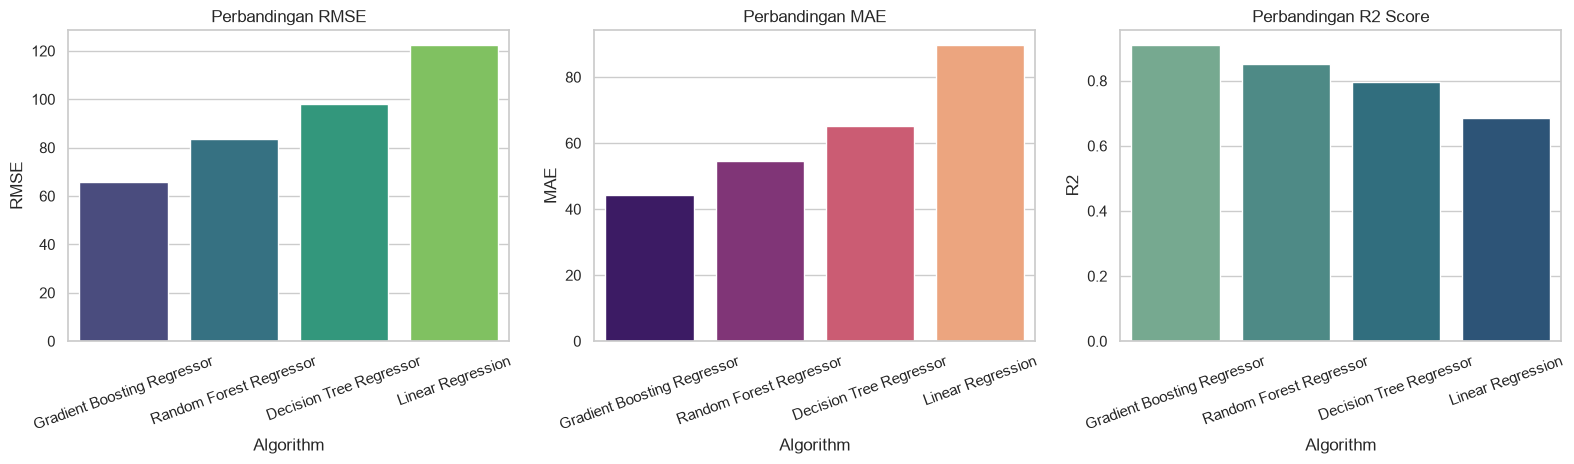

In [7]:
results_df = pd.DataFrame(training_records).sort_values(by=['RMSE', 'MAE'], ascending=[True, True]).reset_index(drop=True)
display(results_df)

best_row = results_df.iloc[0]
best_model_name = str(best_row['Algorithm'])
print(f'Model Terbaik (RMSE Terendah): {best_model_name}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sns.barplot(data=results_df, x='Algorithm', y='RMSE', ax=axes[0], hue='Algorithm', palette='viridis', legend=False)
axes[0].set_title('Perbandingan RMSE')
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(data=results_df, x='Algorithm', y='MAE', ax=axes[1], hue='Algorithm', palette='magma', legend=False)
axes[1].set_title('Perbandingan MAE')
axes[1].tick_params(axis='x', rotation=20)

sns.barplot(data=results_df, x='Algorithm', y='R2', ax=axes[2], hue='Algorithm', palette='crest', legend=False)
axes[2].set_title('Perbandingan R2 Score')
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_algorithm_comparison.png', dpi=150)
plt.show()

## 6. Penyimpanan Artefak Training ke `artifacts/`

In [8]:
joblib.dump(preprocessing_pipeline, ARTIFACTS_DIR / 'preprocessing_pipeline.joblib')
joblib.dump(trained_models, ARTIFACTS_DIR / 'candidate_models.joblib')
predictions_df.to_csv(ARTIFACTS_DIR / 'test_predictions.csv', index=False)

feature_config = {
    'categorical_features': CATEGORICAL_FEATURES,
    'numerical_features': NUMERICAL_FEATURES,
    'feature_order': FEATURE_COLUMNS,
    'target_column': TARGET_COLUMN,
    'transformed_feature_names': transformed_feature_names,
    'split_info': {
        'method': 'chronological_split',
        'train_ratio': TRAIN_RATIO,
        'train_rows': int(len(train_df)),
        'test_rows': int(len(test_df)),
        'train_start': str(train_df['datetime'].min()),
        'train_end': str(train_df['datetime'].max()),
        'test_start': str(test_df['datetime'].min()),
        'test_end': str(test_df['datetime'].max())
    },
    'feature_defaults': {
        'season': 2, 'weather': 1, 'year': int(df['year'].max()), 'month': 6,
        'day': 15, 'hour': 8, 'dayofweek': 2, 'holiday': 0, 'workingday': 1,
        'temp': round(float(df['temp'].median()), 2),
        'atemp': round(float(df['atemp'].median()), 2),
        'humidity': round(float(df['humidity'].median()), 2),
        'windspeed': round(float(df['windspeed'].median()), 2)
    }
}

with open(ARTIFACTS_DIR / 'feature_config.json', 'w', encoding='utf-8') as f:
    json.dump(feature_config, f, indent=2)

with open(ARTIFACTS_DIR / 'training_results.json', 'w', encoding='utf-8') as f:
    json.dump({'best_model_candidate': best_model_name, 'models': training_records}, f, indent=2)

print('Seluruh artefak training berhasil disimpan ke folder artifacts/.')

Seluruh artefak training berhasil disimpan ke folder artifacts/.
